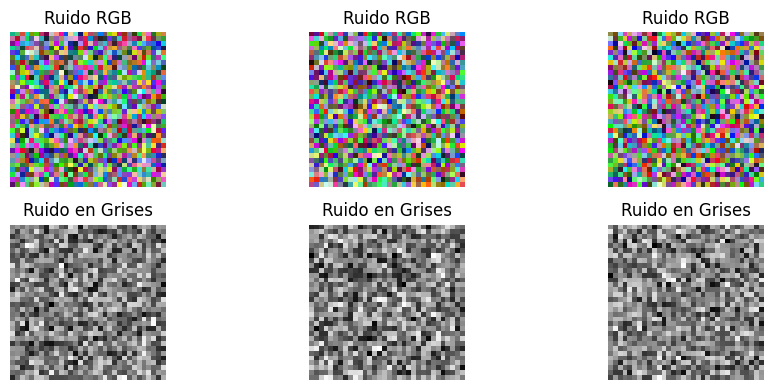

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Capa personalizada (sin pesos entrenables)
class CapaEscalaGrises(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(CapaEscalaGrises, self).__init__(**kwargs)

    def call(self, inputs):
        pesos_rgb = tf.constant([0.2989, 0.5870, 0.1140], dtype=inputs.dtype)
        grises = tf.reduce_sum(inputs * pesos_rgb, axis=-1, keepdims=True)
        return grises

# 2. Pruebas con ruido RGB aleatorio
# Tamaño: 3 imágenes, 32x32 píxeles, 3 canales (Color)
imagenes_prueba = tf.random.uniform(shape=(3, 32, 32, 3), minval=0.0, maxval=1.0)

capa_grises = CapaEscalaGrises()
imagenes_transformadas = capa_grises(imagenes_prueba)

# 3. Visualización
plt.figure(figsize=(10, 4))
for i in range(3):
    plt.subplot(2, 3, i + 1)
    plt.imshow(imagenes_prueba[i]) # Se verá como estática de colores
    plt.title("Ruido RGB")
    plt.axis("off")

    plt.subplot(2, 3, i + 4)
    plt.imshow(tf.squeeze(imagenes_transformadas[i]), cmap="gray") # Se verá como estática blanco y negro
    plt.title("Ruido en Grises")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [2]:
!pip install --upgrade wandb

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: rosi-s-s-09 (rosi-s-s-09-buap) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin



🔗 ENLACE WANDB PARA REPORTE (Prob 2A): https://wandb.ai/rosi-s-s-09-buap/Tarea3-RNA/runs/u6fi4m9x



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


loss,█▅▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,0.00063



🔗 ENLACE WANDB PARA REPORTE (Prob 2B): https://wandb.ai/rosi-s-s-09-buap/Tarea3-RNA/runs/lzsddnc2



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


loss,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,0.00059


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


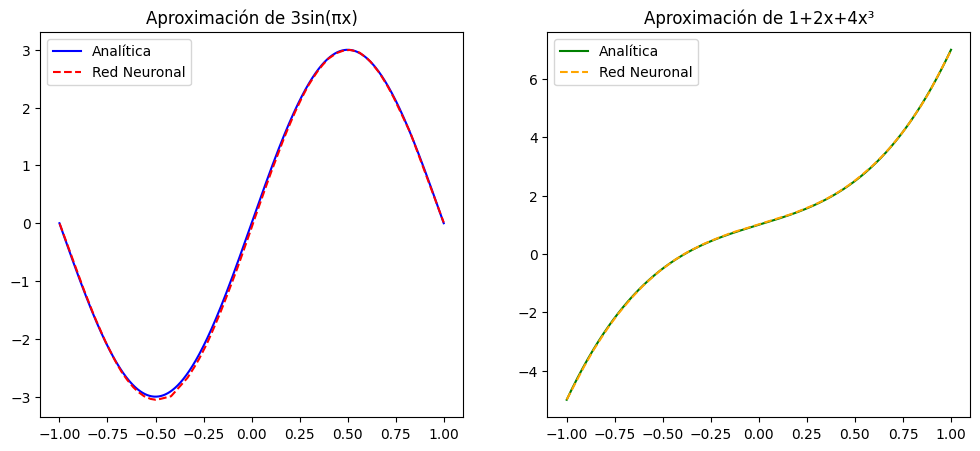

In [6]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import wandb

wandb.login(key="API KEY")

# Datos de entrenamiento en el intervalo [-1, 1]
x_train = np.linspace(-1, 1, 1000).reshape(-1, 1)
y_a = 3 * np.sin(np.pi * x_train)
y_b = 1 + 2 * x_train + 4 * x_train**3

# PROBLEMA 2A: 3sin(πx)
run_a = wandb.init(project="Tarea3-RNA", name="prob2a-seno")
print(f"\n🔗 ENLACE WANDB PARA REPORTE (Prob 2A): {run_a.url}\n")

modelo_a = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1)
])
modelo_a.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01), loss='mse')
historial_a = modelo_a.fit(x_train, y_a, epochs=150, verbose=0)

# Registro manual en WandB
for p in historial_a.history['loss']:
    wandb.log({"loss": p})
wandb.finish()

# PROBLEMA 2B: 1+2x+4x^3
run_b = wandb.init(project="Tarea3-RNA", name="prob2b-polinomio")
print(f"\n🔗 ENLACE WANDB PARA REPORTE (Prob 2B): {run_b.url}\n")

modelo_b = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1)
])
modelo_b.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01), loss='mse')
historial_b = modelo_b.fit(x_train, y_b, epochs=150, verbose=0)

# Registro manual en WandB
for p in historial_b.history['loss']:
    wandb.log({"loss": p})
wandb.finish()

# VISUALIZACIÓN
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(x_train, y_a, label="Analítica", color='blue')
plt.plot(x_train, modelo_a.predict(x_train), label="Red Neuronal", color='red', linestyle='dashed')
plt.title("Aproximación de 3sin(πx)")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(x_train, y_b, label="Analítica", color='green')
plt.plot(x_train, modelo_b.predict(x_train), label="Red Neuronal", color='orange', linestyle='dashed')
plt.title("Aproximación de 1+2x+4x³")
plt.legend()
plt.show()